# 12 — Universal approximation

| | |
| --- | --- |
| **Prerequisites** | Notebooks 00–11, especially `nn.Linear` and the training step (06) and networks of step units (11) |
| **You will learn** | How sums of ReLU "hinges" build any continuous piecewise-linear function; how to set a network's weights by hand so that it interpolates a curve; why the error falls like $1/H^2$ for smooth targets and more slowly for rough ones; what the universal approximation theorem says and, just as important, what it does not say; why depth can be exponentially more efficient than width; why representing a function is not the same as learning it or generalizing from samples |
| **Estimated time** | About 3 hours, plus 1–2 hours for the exercises |
| **Compute** | CPU only, well under a minute. No GPU section: every network here is tiny. |

## Setup

In [1]:
# Setup: make the course helpers importable and record the environment.
import sys
from pathlib import Path

try:
    import dlcourse
except ImportError:  # running without `uv sync`, e.g. on Colab after cloning the repo
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlcourse").is_dir())
    sys.path.insert(0, str(root))
    import dlcourse

import matplotlib.pyplot as plt
import torch

from dlcourse import check, check_close, check_shape, passed, set_seed
from dlcourse.plotting import setup_style

setup_style()
device = dlcourse.describe_environment()
set_seed(0)

Python  3.12.13 (Darwin arm64)
PyTorch 2.14.1
CUDA available: False
MPS available:  True
Selected device: mps


In [2]:
import math

import torch.nn.functional as F
from torch import nn

from dlcourse.data import make_rings
from dlcourse.plotting import COLORS, plot_decision_boundary

## The motivating problem

Notebook 11 showed that networks of step units can represent **any Boolean function** (with up to $2^n$ hidden units) and **any convex polygon** (an AND of half-planes). Those are functions with finitely many outputs. Most quantities we want to predict are not like that: a temperature, a price, the position of a robot arm. They vary continuously.

So we ask four questions about a curve such as $y = \sin x$:

1. Can a neural network represent it, or at least come arbitrarily close?
2. If so, **how many units** does it need for a given accuracy?
3. Does **depth** help, or is one wide hidden layer enough?
4. If a network *can* represent the curve, does that mean we can **learn** it from a few noisy samples?

We answer the first three by **constructing** networks, setting every weight by hand, so nothing depends on whether training succeeds. The fourth needs training, and the answer will be "not necessarily".

Throughout, the hidden units use the **ReLU**, $\operatorname{relu}(z) = \max(z, 0)$, which notebook 02 previewed: it is what makes stacked layers bend instead of collapsing into one affine map.

## 1. ReLU units as building blocks

Start with one input $x$ (a scalar) and one hidden unit. The unit computes $\operatorname{relu}(w x + b)$, and the output layer multiplies it by a weight $a$. As a function of $x$, the result

$$h(x) = a\,\operatorname{relu}(w x + b)$$

is a **hinge**: it is exactly 0 on one side of the point where $w x + b = 0$, and a straight line with slope $a w$ on the other. The **kink** (the corner) sits at

$$x = -\frac{b}{w} \qquad (w \neq 0).$$

If $w > 0$ the unit is **active** (its pre-activation is positive) to the right of the kink; if $w < 0$, to the left. If $w = 0$ the unit outputs the constant $a\,\operatorname{relu}(b)$ and has no kink.

A **one-hidden-layer network** with $H$ hidden units adds up $H$ hinges and a constant $c$:

$$f(x) = \sum_{k=1}^{H} a_k\,\operatorname{relu}(w_k x + b_k) + c.$$

In PyTorch this is `nn.Sequential(nn.Linear(1, H), nn.ReLU(), nn.Linear(H, 1))`. The first layer holds $W_1$ of shape `(H, 1)` (the $w_k$, in `nn.Linear`'s `(out, in)` layout) and $\mathbf b_1$ of shape `(H,)` (the $b_k$); the second holds $W_2$ of shape `(1, H)` (the $a_k$) and a bias of shape `(1,)` (the $c$). `nn.Sequential` simply applies its modules in order. Chapter 3 builds such networks from scratch (notebook 13) and studies activations other than ReLU (notebook 16); here we only need to *set* their weights.

Let us draw three hinges and their sum.

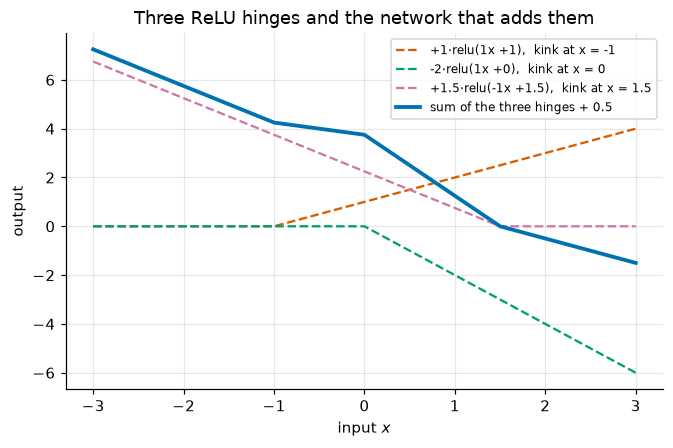

In [3]:
def hinge(x, a, w, b):
    """One ReLU unit times its output weight: a * relu(w x + b). x: (N,) -> (N,)."""
    return a * torch.relu(w * x + b)


xs = torch.linspace(-3, 3, 601)                 # (601,)
units = [(1.0, 1.0, 1.0), (-2.0, 1.0, 0.0), (1.5, -1.0, 1.5)]   # (a, w, b) for each unit
parts = [hinge(xs, a, w, b) for a, w, b in units]
total = sum(parts) + 0.5                        # c = 0.5

fig, ax = plt.subplots(figsize=(7, 4.2))
for (a, w, b), p, col in zip(units, parts, COLORS[1:]):
    ax.plot(xs, p, "--", color=col, label=f"{a:+g}·relu({w:g}x {b:+g}),  kink at x = {-b / w + 0.0:g}")
ax.plot(xs, total, color=COLORS[0], lw=2.5, label="sum of the three hinges + 0.5")
ax.set_xlabel("input $x$")
ax.set_ylabel("output")
ax.set_title("Three ReLU hinges and the network that adds them")
ax.legend(fontsize=8)
plt.show()

Each dashed hinge is flat on one side of its kink. The sum (solid) is **continuous** — no unit can make it jump — and **piecewise linear**, with a kink exactly where some unit has one: at $x = -1$, $0$, and $1.5$. Between kinks it is a straight line.

### How much does the slope change at a kink?

Away from all kinks, the derivative of $f$ is the sum of the slopes of the active units:

$$f'(x) = \sum_{k:\ w_k x + b_k > 0} a_k w_k.$$

Crossing unit $k$'s kink from left to right, a unit with $w_k > 0$ switches **on** (the slope gains $a_k w_k$), and a unit with $w_k < 0$ switches **off** (the slope loses $a_k w_k$, i.e. gains $-a_k w_k$). Both cases say the same thing: the slope **jumps by $a_k |w_k|$** at $x = -b_k/w_k$.

So a one-hidden-layer ReLU network of one variable is a **continuous piecewise-linear (CPWL)** function with **at most $H$ kinks**, and $H + 1$ linear pieces. We check the slope rule on the sum above:

In [4]:
def numerical_slope(f, x, eps=1e-3):
    """Central difference slope of f at x (float, away from kinks)."""
    xx = torch.tensor([x - eps, x + eps], dtype=torch.float64)
    y = f(xx)
    return ((y[1] - y[0]) / (2 * eps)).item()


f_sum = lambda x: sum(hinge(x, a, w, b) for a, w, b in units) + 0.5
for x0 in [-2.0, -0.5, 1.0, 2.5]:
    rule = sum(a * w for a, w, b in units if w * x0 + b > 0)
    print(f"x = {x0:5.1f}: slope from the rule = {rule:5.2f}   numerical slope = {numerical_slope(f_sum, x0):5.2f}")

x =  -2.0: slope from the rule = -1.50   numerical slope = -1.50
x =  -0.5: slope from the rule = -0.50   numerical slope = -0.50
x =   1.0: slope from the rule = -2.50   numerical slope = -2.50
x =   2.5: slope from the rule = -1.00   numerical slope = -1.00


Reading left to right: slope $-1.5$ (only the third unit, $w = -1$, is on); at $x = -1$ the first unit switches on and adds $1$; at $x = 0$ the second adds $-2$; at $x = 1.5$ the third switches off and removes $-1.5$. The jumps are $+1$, $-2$, $+1.5$: exactly $a_k |w_k|$.

One more useful fact: $a\,\operatorname{relu}(w x + b) = a|w|\,\operatorname{relu}\big(\pm(x - t)\big)$ with $t = -b/w$, because $\operatorname{relu}(\lambda z) = \lambda \operatorname{relu}(z)$ for $\lambda > 0$. So we can always take $w = \pm 1$ and put all the scale in $a$. The constructions below use $w = 1$.

### Checkpoint 1.1

By hand first. (a) Where is the kink of $3\,\operatorname{relu}(-2x + 3)$, and is the unit active to its left or its right? Store the kink location in `kink_x`. (b) Evaluate the network

$$f(x) = 2\,\operatorname{relu}(x - 1) - 3\,\operatorname{relu}(x - 2) + \operatorname{relu}(-x) + 0.5$$

at $x = 2.5$ and store it in `f_at_2_5` (a float).

<details>
<summary><b>💡 Hint</b></summary>

(a) Solve $-2x + 3 = 0$. With $w = -2 < 0$ the pre-activation is positive for smaller $x$. (b) At $x = 2.5$ the three pre-activations are $1.5$, $0.5$ and $-2.5$; the last unit is off.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError
print(f"kink at x = {kink_x}, f(2.5) = {f_at_2_5}")

In [ ]:
check_close(kink_x, 1.5, "kink_x")
_x = torch.tensor(2.5)
check_close(f_at_2_5, (2 * torch.relu(_x - 1) - 3 * torch.relu(_x - 2) + torch.relu(-_x) + 0.5).item(), "f_at_2_5")
passed("Checkpoint 1.1")

## 2. Construction: a network that interpolates any curve

Now the reverse question: given a target $f$ on an interval $[a, b]$, choose the weights.

Pick $H + 1$ **knots** $a = t_0 < t_1 < \dots < t_H = b$ and the target's values there, $y_k = f(t_k)$. The **piecewise-linear interpolant** $g$ joins consecutive points $(t_k, y_k)$ with straight segments. On segment $k$ (from $t_k$ to $t_{k+1}$, for $k = 0, \dots, H-1$) its slope is

$$s_k = \frac{y_{k+1} - y_k}{t_{k+1} - t_k}.$$

Section 1 tells us what to do: put a unit with kink at each knot where the slope must change, and choose its output weight to be the **change in slope**.

### Deriving the weights

Take $H$ units $\operatorname{relu}(x - t_k)$, $k = 0, \dots, H - 1$ (so $w_k = 1$ and $b_k = -t_k$), and set

$$g(x) = y_0 + \sum_{k=0}^{H-1} a_k\,\operatorname{relu}(x - t_k), \qquad a_0 = s_0, \qquad a_k = s_k - s_{k-1}\ \ (k \ge 1).$$

**Why this is the interpolant.** For $x$ in segment $j$, the active units are $k = 0, \dots, j$, so the slope of $g$ there is $a_0 + a_1 + \dots + a_j = s_0 + (s_1 - s_0) + \dots + (s_j - s_{j-1}) = s_j$ (the sum *telescopes*). Also $g(t_0) = y_0$, since every unit is off at $t_0$. A continuous function that starts at $y_0$ and has slope $s_j$ on each segment $j$ reaches $y_0 + s_0(t_1 - t_0) = y_1$ at $t_1$, then $y_2$ at $t_2$, and so on: $g(t_k) = y_k$ for every $k$.

So **$H$ hidden units interpolate $H + 1$ knots exactly** on $[t_0, t_H]$. Outside it, $g$ is constant ($= y_0$) to the left, since all units are off, and continues with slope $s_{H-1}$ to the right.

The function below builds this network as an `nn.Sequential` and writes the weights in directly. It works in `float64` on the CPU, so the comparison that follows is limited only by rounding, not by `float32`'s 7 digits.

In [7]:
def interpolating_network(f, knots):
    """One-hidden-layer ReLU network equal to the piecewise-linear interpolant of f at the knots.

    f: maps a (K,) float64 tensor to (K,). knots: (H + 1,) increasing.
    Returns nn.Sequential(Linear(1, H), ReLU, Linear(H, 1)) in float64; input (N, 1) -> output (N, 1).
    """
    t = knots.double()                                   # (H + 1,)
    y = f(t)                                             # (H + 1,) values at the knots
    H = len(t) - 1
    s = (y[1:] - y[:-1]) / (t[1:] - t[:-1])              # (H,) slope of each segment
    a = torch.cat([s[:1], s[1:] - s[:-1]])               # (H,) change of slope at t_0, ..., t_{H-1}
    net = nn.Sequential(
        nn.Linear(1, H, dtype=torch.float64), nn.ReLU(), nn.Linear(H, 1, dtype=torch.float64)
    )
    with torch.no_grad():
        net[0].weight.fill_(1.0)                         # (H, 1): every w_k = 1
        net[0].bias.copy_(-t[:-1])                       # (H,):   b_k = -t_k, kink at t_k
        net[2].weight.copy_(a.unsqueeze(0))              # (1, H): a_k
        net[2].bias.fill_(y[0].item())                   # (1,):   c = y_0
    return net


def run(net, x):
    """Evaluate a 1-input, 1-output network on a 1-D tensor. x: (N,) -> (N,)."""
    with torch.no_grad():
        return net(x.unsqueeze(1).to(net[0].weight.dtype)).squeeze(1)

To test it we need an independent reference. PyTorch has no ready-made 1-D interpolation function, so we write one from two standard operations: `torch.searchsorted(knots, x)` finds, for each $x$, the index of the first knot $\ge x$ (so $x$ lies in the segment ending there), and `torch.lerp(y0, y1, w)` computes $y_0 + w\,(y_1 - y_0)$.

In [8]:
def linear_interp(x, knots, values):
    """Piecewise-linear interpolation through (knots, values), evaluated at x in [knots[0], knots[-1]].

    x: (N,), knots and values: (K,) -> (N,).
    """
    idx = torch.searchsorted(knots, x).clamp(1, len(knots) - 1)   # (N,) right end of each x's segment
    t0, t1 = knots[idx - 1], knots[idx]
    return torch.lerp(values[idx - 1], values[idx], (x - t0) / (t1 - t0))


knots = torch.linspace(-math.pi, math.pi, 9, dtype=torch.float64)    # H + 1 = 9 knots -> H = 8 units
net_sin = interpolating_network(torch.sin, knots)
print(net_sin)
print("first-layer bias (kinks at -b):", [round(v, 3) for v in net_sin[0].bias.tolist()])
print("output weights (slope changes):", [round(v, 3) for v in net_sin[2].weight.squeeze(0).tolist()])

gen = torch.Generator().manual_seed(0)
x_rand = -math.pi + 2 * math.pi * torch.rand(10_000, generator=gen, dtype=torch.float64)   # (10000,)
gap = (run(net_sin, x_rand) - linear_interp(x_rand, knots, torch.sin(knots))).abs().max().item()
print(f"max |network − interpolation| at 10,000 random points: {gap:.1e}")
check(gap < 1e-12, "the constructed network should equal the interpolant up to float64 rounding")
passed("The constructed network is exactly the piecewise-linear interpolant")

Sequential(
  (0): Linear(in_features=1, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=1, bias=True)
)
first-layer bias (kinks at -b): [3.142, 2.356, 1.571, 0.785, -0.0, -0.785, -1.571, -2.356]
output weights (slope changes): [-0.9, 0.527, 0.746, 0.527, 0.0, -0.527, -0.746, -0.527]
max |network − interpolation| at 10,000 random points: 1.3e-15
✅ The constructed network is exactly the piecewise-linear interpolant passed


The two agree to about $10^{-15}$, the rounding level of `float64`: the network does not *approximate* the interpolant, it *is* the interpolant. The printed weights show the recipe: kinks at the 8 left-hand knots, and output weights that are slope changes (the first is the initial slope).

Now three targets of different character, each with 8 units on $[-3, 3]$: the smooth $\sin x$, the kinked $|x|$, and a steep but smooth $\sigma(10x) = 1/(1 + e^{-10x})$.

sin x   max |network − target| on [−3, 3] with 8 units: 0.0663
|x|     max |network − target| on [−3, 3] with 8 units: 0.0000
σ(10x)  max |network − target| on [−3, 3] with 8 units: 0.2578


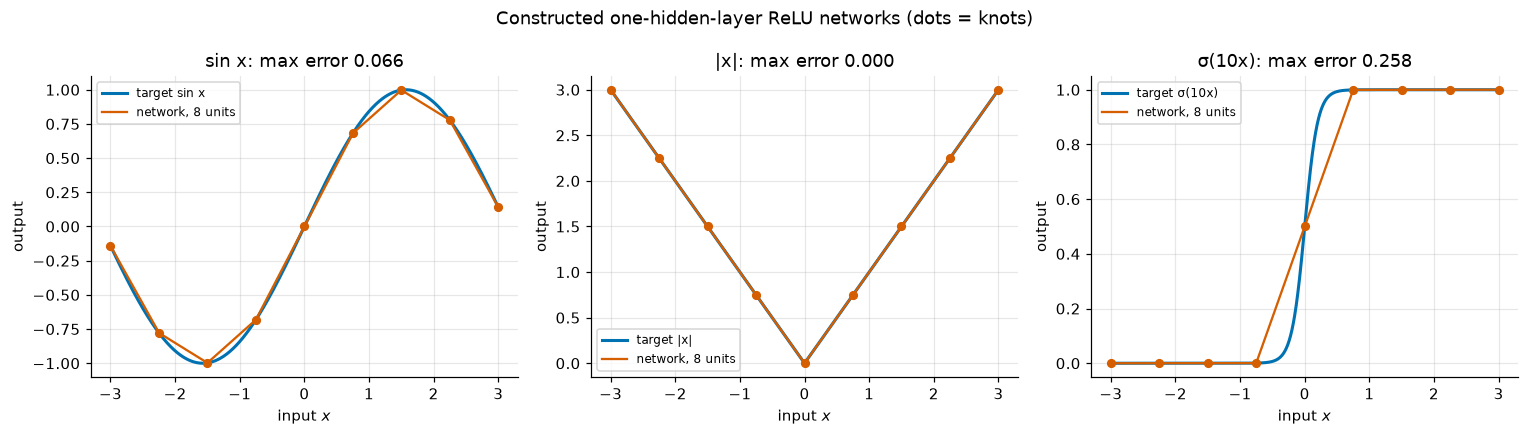

In [9]:
targets = {
    "sin x": torch.sin,
    "|x|": torch.abs,
    "σ(10x)": lambda x: torch.sigmoid(10 * x),
}
H_demo = 8
knots_demo = torch.linspace(-3, 3, H_demo + 1, dtype=torch.float64)
x_dense = torch.linspace(-3, 3, 2001, dtype=torch.float64)       # (2001,) evaluation grid

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, f) in zip(axes, targets.items()):
    net = interpolating_network(f, knots_demo)
    approx = run(net, x_dense)
    err = (approx - f(x_dense)).abs().max().item()
    ax.plot(x_dense, f(x_dense), color=COLORS[0], lw=2, label=f"target {name}")
    ax.plot(x_dense, approx, color=COLORS[1], label=f"network, {H_demo} units")
    ax.plot(knots_demo, f(knots_demo), "o", color=COLORS[1], ms=5)
    ax.set_xlabel("input $x$")
    ax.set_ylabel("output")
    ax.set_title(f"{name}: max error {err:.3f}")
    ax.legend(fontsize=8)
    print(f"{name:7s} max |network − target| on [−3, 3] with {H_demo} units: {err:.4f}")
fig.suptitle("Constructed one-hidden-layer ReLU networks (dots = knots)")
plt.tight_layout()
plt.show()

The network passes through every knot (dots) in all three panels. $|x|$ is reproduced **exactly**, because it is itself piecewise linear with its only kink at a knot ($x = 0$): one unit would be enough. $\sin x$ has a visible error between knots. $\sigma(10x)$ is the worst: it rises from almost 0 to almost 1 between the knots at $-0.75$ and $0.75$, and 8 evenly spaced knots cannot follow that. Section 3 makes this precise.

### Checkpoint 2.1

By hand first: the knots $t = (0, 1, 2, 3)$ with values $y = (0, 1, 3, 2)$ need $H = 3$ units. Compute the output weights `a_small` (a tensor of shape `(3,)`) and the output bias `c_small` (a float) of the interpolating network.

<details>
<summary><b>💡 Hint</b></summary>

The segment slopes are $s = (1, 2, -1)$. The first output weight is $s_0$; the others are $s_1 - s_0$ and $s_2 - s_1$. The bias is $y_0$.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check_shape(a_small, (3,), "a_small")
_net = interpolating_network(lambda t: torch.tensor([0.0, 1.0, 3.0, 2.0], dtype=torch.float64), torch.arange(4.0))
check_close(a_small.double(), _net[2].weight.squeeze(0), "a_small")
check_close(c_small, _net[2].bias.item(), "c_small")
passed("Checkpoint 2.1")

## 3. How fast does the error shrink?

Every continuous target can be interpolated; the question is how many units a given accuracy costs. Measure the **sup-norm error** (the largest error anywhere on the interval):

$$\|f - g\|_\infty = \max_{x \in [a, b]} |f(x) - g(x)|.$$

With equally spaced knots the spacing is $h = (b - a)/H$.

**Claim.** If $f$ has a second derivative with $|f''(x)| \le M$ on $[a, b]$, then

$$\|f - g\|_\infty \le \frac{M h^2}{8}.$$

**Why (a Taylor argument).** Look at one segment $[t_k, t_{k+1}]$ and the error $e(x) = f(x) - g(x)$. It is 0 at both ends, because $g$ interpolates. Suppose $|e|$ is largest at an interior point $x^*$ (if it is largest at an end, it is 0 and there is nothing to prove). At an interior maximum or minimum, $e'(x^*) = 0$. Since $g$ is a straight line on the segment, $e'' = f''$. Now expand $e$ by Taylor's theorem (notebook 03) around $x^*$ out to the **nearer** endpoint $t$, at distance $d = |t - x^*| \le h/2$:

$$0 = e(t) = e(x^*) + e'(x^*)(t - x^*) + \tfrac12 f''(\xi)(t - x^*)^2 = e(x^*) + \tfrac12 f''(\xi)\, d^2$$

for some $\xi$ between $x^*$ and $t$ (the Lagrange form of the remainder). Therefore $|e(x^*)| = \tfrac12 |f''(\xi)|\, d^2 \le \tfrac12 M (h/2)^2 = M h^2/8$. $\blacksquare$

Since $h = (b - a)/H$, the bound is $\frac{M (b-a)^2}{8 H^2}$: **doubling the number of units divides the error by 4.** We check this for $\sin$ on $[-\pi, \pi]$, where $M = 1$.

In [12]:
def max_interp_error(f, a, b, H, n_eval=20001):
    """Sup-norm error of the H-unit interpolating network for f on [a, b], measured on a dense grid."""
    knots = torch.linspace(a, b, H + 1, dtype=torch.float64)
    xe = torch.linspace(a, b, n_eval, dtype=torch.float64)
    return (run(interpolating_network(f, knots), xe) - f(xe)).abs().max().item()


Hs = [4, 8, 16, 32, 64, 128]
err_sin = []
print("   H     measured     bound M h²/8   measured / bound")
for H in Hs:
    h = 2 * math.pi / H
    err_sin.append(max_interp_error(torch.sin, -math.pi, math.pi, H))
    print(f"{H:4d}   {err_sin[-1]:.3e}    {h**2 / 8:.3e}      {err_sin[-1] / (h**2 / 8):.4f}")

   H     measured     bound M h²/8   measured / bound
   4   2.105e-01    3.084e-01      0.6825
   8   7.038e-02    7.711e-02      0.9127
  16   1.885e-02    1.928e-02      0.9777
  32   4.792e-03    4.819e-03      0.9944
  64   1.203e-03    1.205e-03      0.9986
 128   3.011e-04    3.012e-04      0.9996


The measured error never exceeds the bound, and for large $H$ the ratio approaches 1: for $\sin$ the bound is nearly **tight**. That makes sense: the worst segment is where $|\sin''| = |\sin|$ is close to its maximum $M = 1$, and on short segments $f''$ is almost constant, which is exactly the case where the Taylor argument loses nothing.

### Rough targets converge more slowly

The bound needs a bounded second derivative. Take $f(x) = \sqrt{|x|}$ on $[-1, 1]$: continuous, but its slope is infinite at 0. With $H$ even, $x = 0$ is a knot. On the segment $[0, h]$ the interpolant is the line $x/\sqrt h$, and the error $\sqrt x - x/\sqrt h$ is largest where its derivative $\frac{1}{2\sqrt x} - \frac{1}{\sqrt h}$ vanishes, at $x = h/4$:

$$\sqrt{h/4} - \frac{h/4}{\sqrt h} = \frac{\sqrt h}{2} - \frac{\sqrt h}{4} = \frac{\sqrt h}{4}.$$

(On the other segments $f''$ is bounded and the error is smaller.) So the error falls like $h^{1/2} \propto H^{-1/2}$: doubling the units divides it only by $\sqrt 2 \approx 1.41$, not 4. We plot both on log–log axes, where a power law $\text{error} \propto H^{-p}$ is a straight line of slope $-p$.

sqrt|x|: measured ['0.1768', '0.1250', '0.0884', '0.0625', '0.0442', '0.0312']
  predicted √h/4  ['0.1768', '0.1250', '0.0884', '0.0625', '0.0442', '0.0312']
fitted log-log slope: sin -1.910   sqrt|x| -0.500


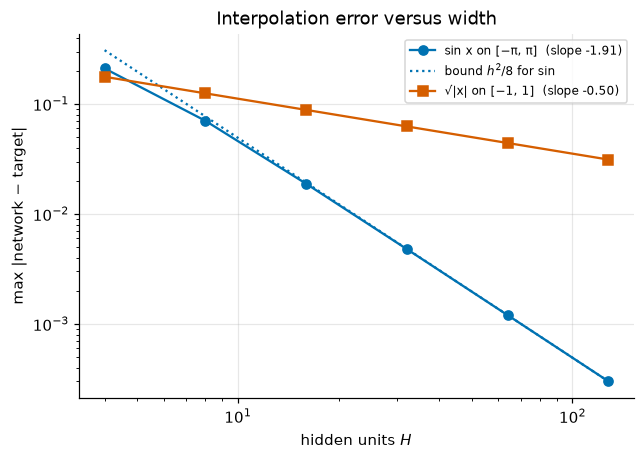

In [13]:
sqrt_abs = lambda x: x.abs().sqrt()
err_sqrt = [max_interp_error(sqrt_abs, -1.0, 1.0, H, n_eval=200_001) for H in Hs]
print("sqrt|x|: measured", [f"{e:.4f}" for e in err_sqrt])
print("  predicted √h/4 ", [f"{math.sqrt(2 / H) / 4:.4f}" for H in Hs])

logH = torch.log(torch.tensor(Hs, dtype=torch.float64))
slope_sin = torch.linalg.lstsq(torch.stack([logH, torch.ones_like(logH)], 1), torch.log(torch.tensor(err_sin, dtype=torch.float64)).unsqueeze(1)).solution[0].item()
slope_sqrt = torch.linalg.lstsq(torch.stack([logH, torch.ones_like(logH)], 1), torch.log(torch.tensor(err_sqrt, dtype=torch.float64)).unsqueeze(1)).solution[0].item()
print(f"fitted log-log slope: sin {slope_sin:.3f}   sqrt|x| {slope_sqrt:.3f}")

fig, ax = plt.subplots(figsize=(6.5, 4.3))
ax.loglog(Hs, err_sin, "o-", label=f"sin x on [−π, π]  (slope {slope_sin:.2f})")
ax.loglog(Hs, [(2 * math.pi / H) ** 2 / 8 for H in Hs], ":", color=COLORS[0], label="bound $h^2/8$ for sin")
ax.loglog(Hs, err_sqrt, "s-", label=f"√|x| on [−1, 1]  (slope {slope_sqrt:.2f})")
ax.set_xlabel("hidden units $H$")
ax.set_ylabel("max |network − target|")
ax.set_title("Interpolation error versus width")
ax.legend(fontsize=8)
plt.show()

Two straight lines with different slopes. For $\sin$ the fitted slope is $-1.91$, close to $-2$: it is a little shallower only because the $H = 4$ and $H = 8$ points sit below the bound, and the ratios of consecutive errors (3.73, 3.93, 3.98, 4.00) approach 4. For $\sqrt{|x|}$ the slope is $-0.5$, matching $\sqrt h/4$ to four digits. Going from 4 to 128 units reduced the $\sin$ error about 700-fold, but the $\sqrt{|x|}$ error only about 6-fold. **How smooth the target is decides how many units an accuracy costs.**

A caveat: this is the rate for *equally spaced* knots. For $\sqrt{|x|}$, placing knots more densely near 0 does much better; choosing where to put the kinks is exactly the freedom a trained network has (and that we test in the chapter problem set).

### Checkpoint 3.1

Using the bound with $M = 1$: (a) compute `bound_sin`, the guaranteed sup-norm error for $\sin$ on $[-\pi, \pi]$ with $H = 20$ equally spaced segments; (b) compute `H_needed`, the smallest integer $H$ for which the bound guarantees an error of at most $10^{-3}$.

<details>
<summary><b>💡 Hint</b></summary>

(a) $h = 2\pi/20$, then $h^2/8$. (b) Solve $\frac{(2\pi/H)^2}{8} \le 10^{-3}$ for $H$: $H \ge 2\pi/\sqrt{8 \cdot 10^{-3}}$, then round **up** with `math.ceil`.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError
print(f"bound for H = 20: {bound_sin:.5f};  H needed for 1e-3: {H_needed}")

In [ ]:
check_close(bound_sin, (2 * math.pi / 20) ** 2 / 8, "bound_sin")
check(isinstance(H_needed, int), "H_needed should be an int")
check((2 * math.pi / H_needed) ** 2 / 8 <= 1e-3, "the bound at H_needed should be at most 1e-3")
check((2 * math.pi / (H_needed - 1)) ** 2 / 8 > 1e-3, "H_needed should be the smallest such H")
check(max_interp_error(torch.sin, -math.pi, math.pi, H_needed) <= 1e-3, "the measured error at H_needed should be at most 1e-3")
passed("Checkpoint 3.1")
print(f"measured error at H = {H_needed}: {max_interp_error(torch.sin, -math.pi, math.pi, H_needed):.6f};"
      f"  at H = {H_needed - 1}: {max_interp_error(torch.sin, -math.pi, math.pi, H_needed - 1):.6f}")

For $\sin$ the bound is so tight that one unit fewer than `H_needed` really does miss the target, by less than 1%.

## 4. The universal approximation theorem

Section 2 already proves a one-dimensional version. Let $f$ be any **continuous** function on $[a, b]$. A continuous function on a closed interval is *uniformly continuous*: for every $\varepsilon > 0$ there is a $\delta > 0$ with $|f(x) - f(x')| < \varepsilon/2$ whenever $|x - x'| \le \delta$. Choose knots with spacing $h \le \delta$. For $x$ in segment $[t_k, t_{k+1}]$, the interpolant $g(x)$ lies between $f(t_k)$ and $f(t_{k+1})$, so

$$|f(x) - g(x)| \le |f(x) - f(t_k)| + |f(t_k) - g(x)| \le |f(x) - f(t_k)| + |f(t_k) - f(t_{k+1})| < \varepsilon.$$

So a one-hidden-layer ReLU network with finitely many units is within $\varepsilon$ of $f$ everywhere on $[a, b]$. No smoothness was needed, only continuity — but without smoothness there is no rate, and $H$ may have to be very large.

### The theorem in general

**Universal approximation theorem.** Let $\sigma$ be a continuous activation function that is **not a polynomial** (ReLU, sigmoid, and tanh all qualify). Let $K \subset \mathbb R^D$ be **compact** (closed and bounded, such as a cube or a ball), and let $f: K \to \mathbb R$ be **continuous**. Then for every $\varepsilon > 0$ there are a finite width $H$ and parameters $\mathbf w_k \in \mathbb R^D$, $b_k, a_k, c \in \mathbb R$ such that

$$\sup_{\mathbf x \in K} \Big| f(\mathbf x) - \Big(\sum_{k=1}^{H} a_k\,\sigma(\mathbf w_k \cdot \mathbf x + b_k) + c\Big) \Big| < \varepsilon.$$

History: Cybenko (1989) proved it for sigmoid-shaped activations; Hornik, Stinchcombe and White (1989) and Hornik (1991) extended it to broad classes of bounded activations; Leshno, Lin, Pinkus and Schocken (1993) showed that a (mildly regular) activation gives universal approximation **if and only if it is not a polynomial**, which covers the ReLU. (Stated without proof in $D > 1$; the proofs use functional analysis beyond this course.) Why not polynomials: a network with a polynomial activation of degree $p$ is itself a polynomial of degree at most $p$, however wide it is, so it cannot approximate, say, a polynomial of degree $p + 1$.

### Reading the assumptions carefully

- **Continuous target.** Discontinuous targets are not covered; see below.
- **Compact domain.** The guarantee is about a bounded region only. Outside $K$, the network can do anything (Section 6 shows a ReLU network becoming a straight line).
- **Sup norm.** "Within $\varepsilon$" means *everywhere* on $K$, the strongest usual sense.
- **Width unbounded.** $H$ depends on $f$ and $\varepsilon$ and may be enormous.

### What it does **not** say

1. **How many units.** Nothing. Section 3 showed that the count depends on smoothness; in $D$ dimensions, grid-like constructions need on the order of $(1/h)^D$ units, exponential in $D$ — just like the up-to-$2^n$ units for Boolean functions in notebook 11.
2. **How to find the weights.** It is an existence statement. Whether gradient descent finds such weights is a separate question (Section 6, and Chapter 3).
3. **Anything about unseen data.** It assumes we know $f$ everywhere. From finitely many noisy samples, many networks fit equally well and disagree elsewhere (Section 6; notebook 22).
4. **Exact representation of discontinuous functions.** A class label that jumps from 0 to 1 is not continuous; we look at this next.

### A jump cannot be approximated in the sup norm

Let $s(x) = 0$ for $x < 0$ and $s(x) = 1$ for $x \ge 0$ (a step, like notebook 07's perceptron output), and let $g$ be **any** continuous function on $[-1, 1]$ with $|s(x) - g(x)| < \varepsilon$ for all $x$. For $x < 0$ this says $g(x) < \varepsilon$; letting $x \to 0$ from the left and using continuity, $g(0) \le \varepsilon$. At $x = 0$ it says $g(0) > 1 - \varepsilon$. Both hold only if $1 - \varepsilon < \varepsilon$, i.e. $\varepsilon > 1/2$.

So **no continuous function — and every network with continuous activations is continuous — gets within $1/2$ of a step everywhere**, let alone within $0.4$. The universal approximation theorem does not apply because its hypothesis (continuous $f$) fails.

What *is* possible is approximation where the error is large only on a tiny set. Take the ramp, built from two ReLU units,

$$g_\delta(x) = \frac{\operatorname{relu}(x + \delta) - \operatorname{relu}(x - \delta)}{2\delta},$$

which is 0 for $x \le -\delta$, 1 for $x \ge \delta$, and linear in between. Its error is nonzero only on $(-\delta, \delta)$. The integrated squared error is $\int_{-1}^{1} (s - g_\delta)^2\,dx = 2\int_0^\delta \big(\tfrac12 - \tfrac{x}{2\delta}\big)^2 dx = \delta/6$, which goes to 0 with $\delta$.

In [16]:
def step(x):
    return (x >= 0).to(x.dtype)


def ramp(x, delta):
    """Two-unit ReLU network: 0 for x <= -delta, 1 for x >= delta, linear between. x: (N,) -> (N,)."""
    return (torch.relu(x + delta) - torch.relu(x - delta)) / (2 * delta)


x_step = torch.arange(-200_000, 200_001, dtype=torch.float64) / 200_000   # (400001,) on [-1, 1], contains x = 0 exactly
dx = 2 / (len(x_step) - 1)
print("  delta   sup error   ∫(s − g)² dx   (δ/6)   thresholded at 0.5: wrong points")
for delta in [0.5, 0.1, 0.01, 0.001]:
    g = ramp(x_step, delta)
    err = step(x_step) - g
    wrong = ((g >= 0.5).to(x_step.dtype) != step(x_step)).sum().item()
    print(f"{delta:7.3f}   {err.abs().max().item():.4f}     {(err**2).sum().item() * dx:.6f}     {delta / 6:.6f}   {wrong}")

  delta   sup error   ∫(s − g)² dx   (δ/6)   thresholded at 0.5: wrong points
  0.500   0.5000     0.083333     0.083333   0
  0.100   0.5000     0.016667     0.016667   0
  0.010   0.5000     0.001667     0.001667   0
  0.001   0.5000     0.000167     0.000167   0


Three facts in one table. The **sup error stays at exactly $0.5$** however small $\delta$ gets (at $x = 0$, $g_\delta(0) = 1/2$ while $s(0) = 1$), as the argument above says it must. The **integrated squared error** matches $\delta/6$ and goes to 0: in that weaker, "on average" sense, networks *can* approximate steps arbitrarily well. And the **thresholded** network, $g_\delta(x) \ge 1/2$, gets **every** point right: a classifier only needs the output on the correct side of a threshold, not equal to the label. That is how notebook 11's step-unit networks represented regions exactly, and how a sigmoid output (notebook 09) gives exact class *decisions* while its probabilities stay continuous.

### Checkpoint 4.1

A different continuous approximant of the step: $\sigma(50x)$, the logistic sigmoid of notebook 09. On the grid `x_step`, compute `sup_err_sig`, the largest $|s(x) - \sigma(50x)|$, and `frac_close`, the fraction of grid points where that error is below $0.01$. Predict `sup_err_sig` before running.

<details>
<summary><b>💡 Hint</b></summary>

`err = (step(x_step) - torch.sigmoid(50 * x_step)).abs()`. Then `.max()` and `(err < 0.01).double().mean()`. At $x = 0$, what is $\sigma(0)$?

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError
print(f"sup error {sup_err_sig:.4f}, fraction of points within 0.01: {frac_close:.4f}")

In [ ]:
_err = (step(x_step) - torch.sigmoid(50 * x_step)).abs()
check_close(sup_err_sig, _err.max().item(), "sup_err_sig")
check_close(frac_close, (_err < 0.01).double().mean().item(), "frac_close")
check(sup_err_sig >= 0.5 - 1e-12, "no continuous function gets within 1/2 of a step everywhere")
passed("Checkpoint 4.1")

About 91% of the interval is within 0.01 of the step (everywhere except $|x| < \ln(99)/50 \approx 0.092$, where $\sigma(50x)$ is between 0.01 and 0.99), yet the worst point is off by exactly $1/2$. Making the sigmoid steeper shrinks the bad region but never its worst error.

### In two dimensions: towers

The same ideas work for inputs $\mathbf x \in \mathbb R^2$. One visual construction builds a **tower** over each cell of a grid: a function that is 1 on the cell and 0 away from it. Adding towers weighted by the target's value on each cell gives a piecewise-constant approximation, like a bar chart in 2-D.

- **Layer 1** (ReLUs of $x_1$ or of $x_2$ alone): a **trapezoid** $u_i(x_1)$ that is 1 across cell column $i$ and ramps to 0 over a width $\delta$ at its edges uses 4 ReLU units — two ramps like $g_\delta$, one up and one down. Similarly $v_j(x_2)$ for cell row $j$.
- **Layer 2:** $T_{ij}(\mathbf x) = \operatorname{relu}\big(u_i(x_1) + v_j(x_2) - 1\big)$ is 1 where both trapezoids are 1 (inside cell $(i, j)$) and 0 where either is 0 — a soft AND, as in notebook 11.
- **Output:** $\sum_{i,j} f_{ij}\, T_{ij}(\mathbf x)$, with $f_{ij}$ the target's value at the cell's center.

This uses **two** hidden layers because it is easy to see; the theorem guarantees that one hidden layer also suffices, but one-layer constructions in 2-D are much less transparent. We apply it to the **concentric rings** of `make_rings` (two classes at radii 0.5 and 1), taking as target the region outside the circle of radius $0.75$, which separates the two rings.

In [19]:
def tower_network(cell_values, lo, hi, delta):
    """Two-hidden-layer ReLU network: sum_ij cell_values[i, j] * tower over grid cell (i, j) of [lo, hi]^2.

    cell_values: (n, n), entry [i, j] for the cell in column i (x_1) and row j (x_2).
    Input (P, 2) -> output (P, 1), float64.
    """
    n = cell_values.shape[0]
    edges = torch.linspace(lo, hi, n + 1, dtype=torch.float64)          # (n + 1,) cell boundaries
    # Layer 1: for each axis and each cell, 4 ReLUs relu(x_axis - kink) with these kinks and output coefficients.
    kinks = torch.stack([edges[:-1] - delta / 2, edges[:-1] + delta / 2,
                         edges[1:] - delta / 2, edges[1:] + delta / 2], dim=1)   # (n, 4)
    coefs = torch.tensor([1.0, -1.0, -1.0, 1.0], dtype=torch.float64) / delta   # trapezoid = coefs · relus
    H1 = 2 * n * 4
    layer1 = nn.Linear(2, H1, dtype=torch.float64)
    layer2 = nn.Linear(H1, n * n, dtype=torch.float64)
    out = nn.Linear(n * n, 1, dtype=torch.float64)
    with torch.no_grad():
        W1 = torch.zeros(H1, 2, dtype=torch.float64)
        W1[: 4 * n, 0] = 1.0                                             # first 4n units look at x_1
        W1[4 * n :, 1] = 1.0                                             # last 4n units look at x_2
        layer1.weight.copy_(W1)
        layer1.bias.copy_(-torch.cat([kinks.reshape(-1), kinks.reshape(-1)]))
        W2 = torch.zeros(n, n, H1, dtype=torch.float64)                  # tower (i, j) reads u_i and v_j
        for i in range(n):
            W2[i, :, 4 * i : 4 * i + 4] = coefs                          # + u_i(x_1)
            W2[:, i, 4 * n + 4 * i : 4 * n + 4 * i + 4] = coefs          # + v_i(x_2) for row i
        layer2.weight.copy_(W2.reshape(n * n, H1))
        layer2.bias.fill_(-1.0)
        out.weight.copy_(cell_values.reshape(1, n * n))
        out.bias.zero_()
    return nn.Sequential(layer1, nn.ReLU(), layer2, nn.ReLU(), out)


X_rings, y_rings = make_rings(n=300, seed=0)                            # (600, 2), (600,)
lo, hi = -1.25, 1.25
results = {}
for n_cells in [6, 12, 24]:
    centers = lo + (torch.arange(n_cells, dtype=torch.float64) + 0.5) * (hi - lo) / n_cells
    C1, C2 = torch.meshgrid(centers, centers, indexing="ij")           # (n, n) each: [i, j] = (x_1 center, x_2 center)
    cell_values = ((C1**2 + C2**2).sqrt() > 0.75).double()             # target on each cell: outside radius 0.75
    tnet = tower_network(cell_values, lo, hi, delta=0.02 * (hi - lo) / n_cells)
    predict = lambda P, tnet=tnet: (tnet(P.double()).squeeze(1) >= 0.5).long()
    with torch.no_grad():
        acc = (predict(X_rings) == y_rings).double().mean().item()
    units = sum(m.out_features for m in tnet if isinstance(m, nn.Linear)) - 1
    results[n_cells] = (tnet, predict, acc, units)
    print(f"{n_cells:2d}×{n_cells:<2d} cells: hidden units = {8 * n_cells} + {n_cells**2} = {units:4d}   accuracy on the rings = {acc:.3f}")
circle_acc = ((X_rings.norm(dim=1) > 0.75).long() == y_rings).double().mean().item()
print(f"exact circle of radius 0.75 (the target itself): accuracy = {circle_acc:.3f}")

 6×6  cells: hidden units = 48 + 36 =   84   accuracy on the rings = 0.963
12×12 cells: hidden units = 96 + 144 =  240   accuracy on the rings = 0.977
24×24 cells: hidden units = 192 + 576 =  768   accuracy on the rings = 0.987
exact circle of radius 0.75 (the target itself): accuracy = 0.992


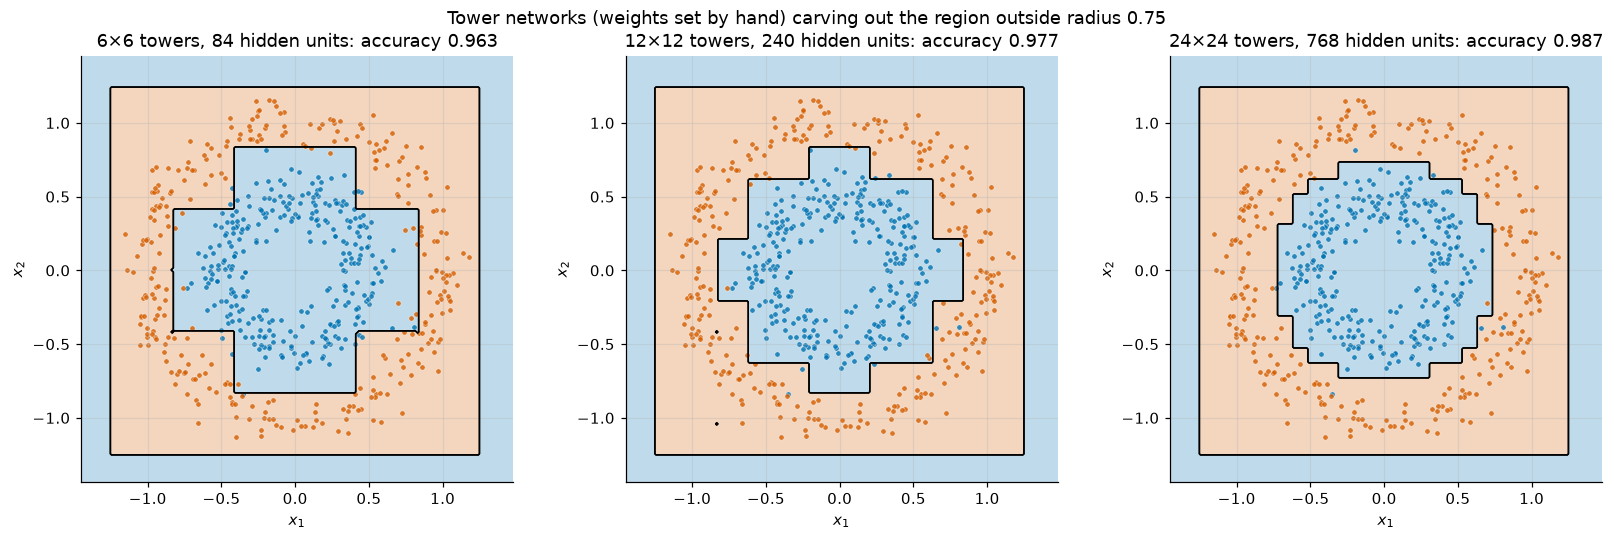

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, (n_cells, (tnet, predict, acc, units)) in zip(axes, results.items()):
    plot_decision_boundary(predict, X_rings, y_rings, ax=ax, kind="label",
                           title=f"{n_cells}×{n_cells} towers, {units} hidden units: accuracy {acc:.3f}")
fig.suptitle("Tower networks (weights set by hand) carving out the region outside radius 0.75")
plt.tight_layout()
plt.show()

The towers tile the square $[-1.25, 1.25]^2$, so the decision region is a **pixelated circle**: with $6 \times 6$ cells it is a crude cross; with $24 \times 24$ it is close to the true circle, and the accuracy (0.987) approaches that of the exact circle (0.992; the rings' noise puts a few points on the wrong side of radius 0.75, which no classifier with this boundary can get right). Outside the square there are no towers, the output is 0, and the network predicts the inner class: the construction covers only the compact set it was built on. (Where four cells meet, the $\delta$-wide seams can dip below the 0.5 threshold in tiny specks; they shrink with $\delta$.)

Look at the unit counts: the second layer has one unit per cell, $n^2$ in 2-D. Halving the cell size quadruples it; in $D$ dimensions it would multiply by $2^D$. This is the **curse of dimensionality** for grid-based constructions: about $(1/h)^D$ units for resolution $h$.

## 5. Width versus depth

Everything so far used one or two hidden layers and made them **wide**. Does stacking layers buy anything for functions of one variable? Here is a striking example (Telgarsky, 2016).

The **tent map** on $[0, 1]$ is

$$T(x) = 2\,\operatorname{relu}(x) - 4\,\operatorname{relu}(x - \tfrac12) = \begin{cases} 2x & 0 \le x \le \tfrac12 \\ 2 - 2x & \tfrac12 \le x \le 1 \end{cases}$$

— two ReLU units, one kink at $\tfrac12$, mapping $[0, 1]$ onto $[0, 1]$. Now **compose** it: $T^{(k)} = T \circ T \circ \dots \circ T$ ($k$ times). Each application doubles the number of linear pieces: as $x$ sweeps across a piece of $T^{(k-1)}$, the value $T^{(k-1)}(x)$ sweeps all of $[0, 1]$, so the next $T$ folds that piece into two. Hence $T^{(k)}$ has $2^k$ linear pieces ($2^{k-1}$ "teeth").

As a network, each $T$ is a `Linear(1, 2)` → ReLU → `Linear(2, 1)` block; stacking $k$ blocks is a network with $k$ hidden layers of width 2, **$2k$ ReLU units in total**. (Each `Linear(2, 1)` followed by the next block's `Linear(1, 2)` could be merged into a single `Linear(2, 2)`, since two affine maps collapse into one, notebook 02.)

In [21]:
def tent_power(k):
    """Depth-k ReLU network computing the k-fold composition of the tent map. Input (N, 1) -> (N, 1), float64."""
    layers = []
    for _ in range(k):
        first, second = nn.Linear(1, 2, dtype=torch.float64), nn.Linear(2, 1, dtype=torch.float64)
        with torch.no_grad():
            first.weight.copy_(torch.tensor([[1.0], [1.0]]))       # (2, 1)
            first.bias.copy_(torch.tensor([0.0, -0.5]))             # kinks at 0 and 1/2
            second.weight.copy_(torch.tensor([[2.0, -4.0]]))       # (1, 2): 2 relu(x) - 4 relu(x - 1/2)
            second.bias.zero_()
        layers += [first, nn.ReLU(), second]
    return nn.Sequential(*layers)


def count_pieces_dyadic(net, k):
    """Count linear pieces of a network on [0, 1] using a grid that contains every multiple of 2^-k."""
    x = torch.linspace(0, 1, 2**12 + 1, dtype=torch.float64)       # spacing 2^-12: all kinks are grid points
    slopes = torch.diff(run(net, x)) / torch.diff(x)               # (2^12,) one slope per grid cell
    return int((torch.diff(slopes).abs() > 1e-6).sum().item()) + 1


print(" k   linear pieces   ReLU units (deep)   min units, one hidden layer")
for k in range(1, 7):
    pieces = count_pieces_dyadic(tent_power(k), k)
    print(f"{k:2d}   {pieces:6d}          {2 * k:4d}                {pieces - 1:6d}")

 k   linear pieces   ReLU units (deep)   min units, one hidden layer
 1        2             2                     1
 2        4             4                     3
 3        8             6                     7
 4       16             8                    15
 5       32            10                    31
 6       64            12                    63


Because every kink of $T^{(k)}$ lies at a multiple of $2^{-k}$, and our grid of spacing $2^{-12}$ contains all of those points exactly in binary floating point, each grid cell lies inside one linear piece and the counted slope changes are exactly the kinks. The count is $2^k$ for every $k$.

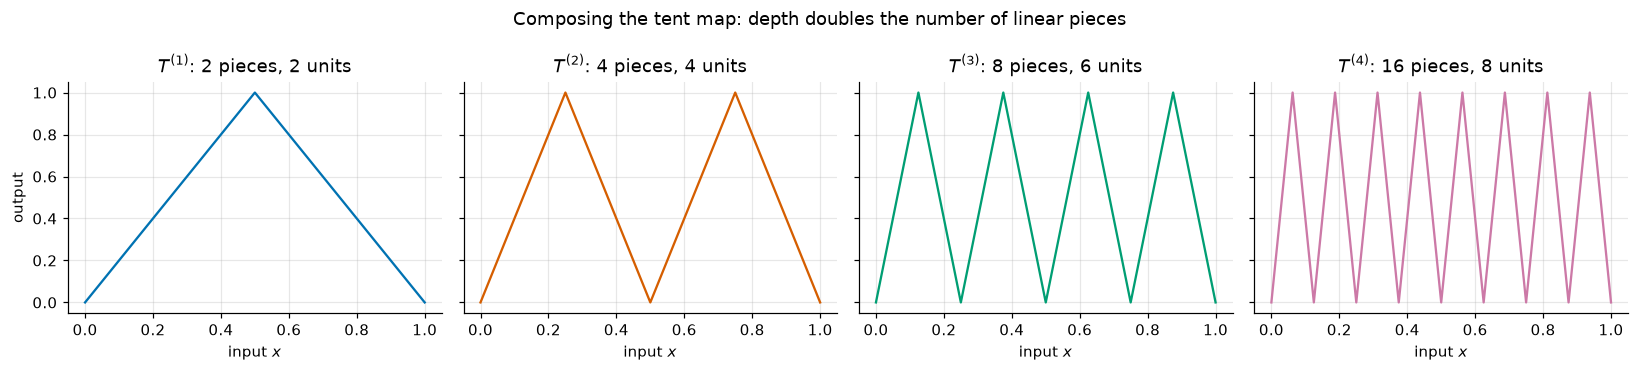

In [22]:
x01 = torch.linspace(0, 1, 2049, dtype=torch.float64)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, k in zip(axes, range(1, 5)):
    ax.plot(x01, run(tent_power(k), x01), color=COLORS[k - 1])
    ax.set_xlabel("input $x$")
    ax.set_title(f"$T^{{({k})}}$: {2**k} pieces, {2 * k} units")
axes[0].set_ylabel("output")
fig.suptitle("Composing the tent map: depth doubles the number of linear pieces")
plt.tight_layout()
plt.show()

Every extra layer (2 more units) doubles the number of teeth.

### Why one hidden layer needs exponentially many units

Section 1 showed that a one-hidden-layer network $\sum_k a_k \operatorname{relu}(w_k x + b_k) + c$ has a kink only where some unit has one, at most one kink per unit. So with $H$ units it has **at most $H$ kinks, hence at most $H + 1$ linear pieces**. To represent $T^{(k)}$ with its $2^k$ pieces, a one-hidden-layer network needs **at least $2^k - 1$ units**, against $2k$ for the deep network. For $k = 20$: 40 units deep, at least 1,048,575 shallow.

And $2^k$ units are enough, using Section 2: interpolate $T^{(k)}$ at the $2^k + 1$ knots $j/2^k$.

In [23]:
k = 5
knots_tent = torch.linspace(0, 1, 2**k + 1, dtype=torch.float64)
shallow = interpolating_network(lambda t: run(tent_power(k), t), knots_tent)
x_test = torch.rand(10_000, generator=torch.Generator().manual_seed(1), dtype=torch.float64)
gap = (run(shallow, x_test) - run(tent_power(k), x_test)).abs().max().item()
print(f"one hidden layer: {shallow[0].out_features} units;  deep: {2 * k} units;  max difference {gap:.1e}")

one hidden layer: 32 units;  deep: 10 units;  max difference 2.1e-14


The two networks compute the same function (up to rounding), with 32 units in one layer versus 10 spread over 5 layers. Telgarsky (2016) proved a stronger statement, given here without proof: shallow networks cannot even *approximate* such sawtooth functions well unless they have exponentially many units.

Two cautions. First, this shows that depth is *sometimes* exponentially more efficient, for very oscillatory functions; it does not mean every function benefits. Second, the deep network's pieces are not independent: $T^{(k)}$ is periodic and highly structured. A deep network with few units cannot produce $2^k$ *arbitrary* pieces. Notebook 20 investigates when depth helps in practice.

### Checkpoint 5.1

For $k = 7$ compositions of the tent map, store: `pieces_7`, the number of linear pieces on $[0, 1]$; `deep_units_7`, the number of ReLU units in `tent_power(7)`; and `shallow_min_7`, the smallest number of units a one-hidden-layer network needs to represent it exactly.

<details>
<summary><b>💡 Hint</b></summary>

Pieces double with each composition, starting from 2 for $k = 1$. Each block has 2 units. A one-hidden-layer network with $H$ units has at most $H + 1$ pieces.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check(pieces_7 == count_pieces_dyadic(tent_power(7), 7), "pieces_7 does not match the counted number of pieces")
check(deep_units_7 == sum(m.out_features for m in tent_power(7) if isinstance(m, nn.Linear) and m.out_features == 2),
      "deep_units_7 should count the hidden ReLU units of tent_power(7)")
check(shallow_min_7 == pieces_7 - 1, "a one-hidden-layer network with H units has at most H + 1 pieces")
passed("Checkpoint 5.1")

## 6. Representing ≠ learning ≠ generalizing

Sections 2–5 **constructed** networks from full knowledge of the target. In practice we have only **samples**, often noisy, and we **train**. Three distinct questions:

- **Representing:** does some setting of the weights approximate the target? (Sections 2–5: yes.)
- **Learning:** does an optimizer *find* such weights from the data?
- **Generalizing:** do the weights it finds work on inputs that were **not** in the training data?

The data: $N = 20$ equally spaced inputs on $[-\pi, \pi]$ with targets $y_i = \sin x_i + \varepsilon_i$, $\varepsilon_i \sim \mathcal N(0, 0.15^2)$. We judge every model on a dense grid of 2,001 points, comparing with the noise-free $\sin$: these are held-out inputs the model never trained on, and the training error alone cannot tell us how a model behaves *between* the samples. (Notebook 22 treats train/test splits properly.)

In [26]:
N_train, NOISE = 20, 0.15
gen = torch.Generator().manual_seed(0)
x_train = torch.linspace(-math.pi, math.pi, N_train)                   # (20,)
y_train = torch.sin(x_train) + NOISE * torch.randn(N_train, generator=gen)
X_train, Y_train = x_train.unsqueeze(1), y_train.unsqueeze(1)          # (20, 1) each
x_grid = torch.linspace(-math.pi, math.pi, 2001)                       # (2001,) held-out inputs
X_grid, Y_grid = x_grid.unsqueeze(1), torch.sin(x_grid).unsqueeze(1)   # (2001, 1), noise-free truth


def test_mse(f_vals):
    """MSE against the noise-free sin on the dense grid. f_vals: (2001,)."""
    return ((f_vals.float() - torch.sin(x_grid)) ** 2).mean().item()


# Representation: 19 units interpolating the *noise-free* sin at the 20 training inputs.
clean_net = interpolating_network(torch.sin, x_train.double())
# Interpolating the *noisy* targets: also 19 units, and zero training error by construction.
noisy_net = interpolating_network(lambda t: y_train.double(), x_train.double())
print(f"constructed, noise-free knots: test MSE {test_mse(run(clean_net, x_grid.double())):.5f}")
print(f"constructed, noisy targets:    train MSE {((run(noisy_net, x_train.double()) - y_train.double())**2).mean().item():.1e}"
      f"   test MSE {test_mse(run(noisy_net, x_grid.double())):.5f}")

constructed, noise-free knots: test MSE 0.00005
constructed, noisy targets:    train MSE 1.5e-30   test MSE 0.02076


A 19-unit network that is within $5 \cdot 10^{-5}$ (in MSE) of $\sin$ **exists**: representation is not the problem. But the network that interpolates the noisy targets has training error 0 and a test error of about $0.02$ — roughly the noise variance $0.15^2 = 0.0225$, because between samples it follows the noise, not the curve.

Now train. A network with $H = 50$ units, Adam (an adaptive variant of gradient descent, notebook 19) with learning rate 0.01, full batch, MSE loss, for 20,000 steps — about a second on a laptop CPU. We record the training and test MSE every 50 steps and keep snapshots of the network at steps 200 and 20,000.

In [27]:
torch.manual_seed(0)
model = nn.Sequential(nn.Linear(1, 50), nn.ReLU(), nn.Linear(50, 1))
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
history, snapshots = [], {}
for step_i in range(1, 20_001):
    optimizer.zero_grad()
    loss = F.mse_loss(model(X_train), Y_train)
    loss.backward()
    optimizer.step()
    if step_i % 50 == 0:
        with torch.no_grad():
            history.append((step_i, F.mse_loss(model(X_train), Y_train).item(), F.mse_loss(model(X_grid), Y_grid).item()))
    if step_i in (200, 20_000):
        snapshots[step_i] = [p.detach().clone() for p in model.parameters()]

history = torch.tensor(history)                                        # (400, 3): step, train MSE, test MSE
best = history[history[:, 2].argmin()]
print(f"best test MSE {best[2].item():.4f} at step {int(best[0].item())} (train MSE {best[1].item():.4f})")
print(f"after 20,000 steps: train MSE {history[-1, 1].item():.5f}   test MSE {history[-1, 2].item():.4f}")


def model_at(step_i):
    """A copy of the 50-unit model with the parameters saved at the given step."""
    m = nn.Sequential(nn.Linear(1, 50), nn.ReLU(), nn.Linear(50, 1))
    with torch.no_grad():
        for p, saved in zip(m.parameters(), snapshots[step_i]):
            p.copy_(saved)
    return m


model_early, model_long = model_at(200), model_at(20_000)

best test MSE 0.0131 at step 50 (train MSE 0.0154)
after 20,000 steps: train MSE 0.00010   test MSE 0.0242


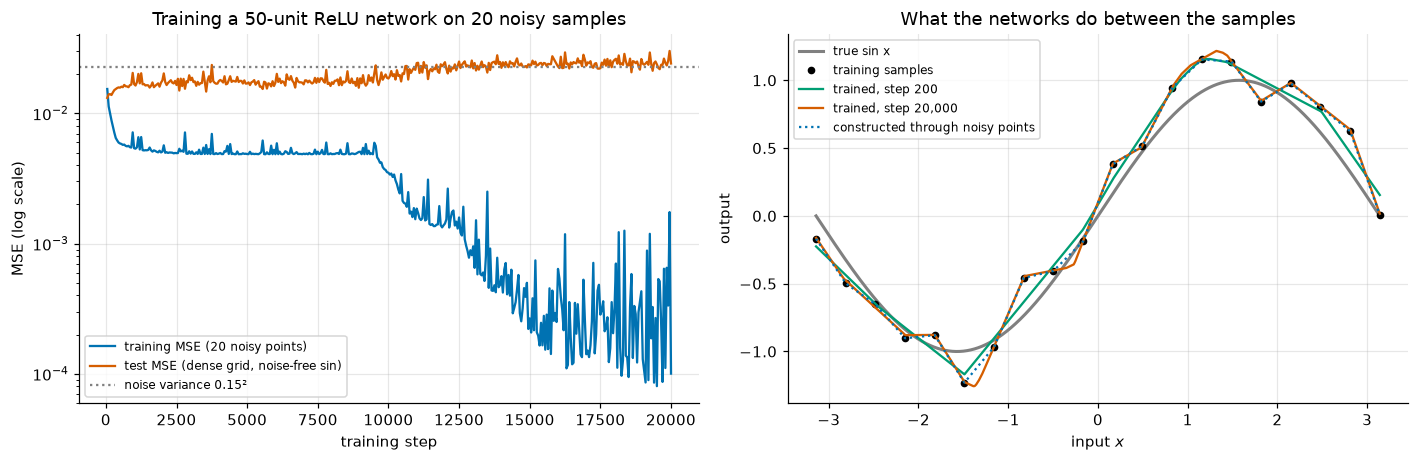

In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3))
ax1.semilogy(history[:, 0], history[:, 1], label="training MSE (20 noisy points)")
ax1.semilogy(history[:, 0], history[:, 2], label="test MSE (dense grid, noise-free sin)")
ax1.axhline(NOISE**2, color="gray", ls=":", label="noise variance 0.15²")
ax1.set_xlabel("training step")
ax1.set_ylabel("MSE (log scale)")
ax1.set_title("Training a 50-unit ReLU network on 20 noisy samples")
ax1.legend(fontsize=8)

ax2.plot(x_grid, torch.sin(x_grid), color="gray", lw=2, label="true sin x")
ax2.plot(x_train, y_train, "o", color="k", ms=4, label="training samples")
ax2.plot(x_grid, run(model_early, x_grid), color=COLORS[2], label="trained, step 200")
ax2.plot(x_grid, run(model_long, x_grid), color=COLORS[1], label="trained, step 20,000")
ax2.plot(x_grid, run(noisy_net, x_grid.double()), ":", color=COLORS[0], label="constructed through noisy points")
ax2.set_xlabel("input $x$")
ax2.set_ylabel("output")
ax2.set_title("What the networks do between the samples")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

Left: the training error falls in two stages to about $10^{-4}$, more than 200 times below the noise variance, while the test error is lowest in the first few hundred steps (0.013 at step 50) and then **rises** to about 0.024: the network is fitting the noise. Right: at step 200 the trained network is a coarse piecewise-linear curve that roughly follows the samples; after 20,000 steps it threads almost every noisy sample and adds extra bends between them (near $x = -1.4$ and $x = 1.3$), nearly coinciding with the constructed network through the noisy points.

Three lessons. **Low training error is not the goal**; error on unseen inputs is. **Training found a good representation only by stopping early** — nothing in the loss told it to stop. And whether gradient descent reaches a *particular* function, such as the clean interpolant that we know exists, is not guaranteed by any approximation theorem; the chapter problem set measures how close training gets.

### Outside the training interval

The theorem is about a compact set. What does a ReLU network do outside it? Far to the right, every unit with $w_k > 0$ is on and every unit with $w_k < 0$ is off, so the network is exactly linear there, with slope $\sum_{k: w_k > 0} a_k w_k$ (Section 1). Far to the left it is linear with slope $\sum_{k: w_k < 0} a_k w_k$. A ReLU network **extrapolates linearly**, whatever the target does.

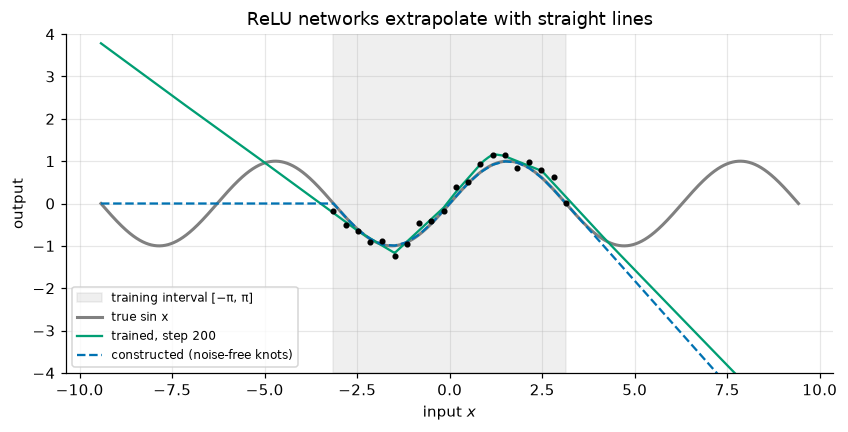

In [29]:
x_wide = torch.linspace(-3 * math.pi, 3 * math.pi, 3001)              # (3001,)
fig, ax = plt.subplots(figsize=(9, 4))
ax.axvspan(-math.pi, math.pi, color="gray", alpha=0.12, label="training interval [−π, π]")
ax.plot(x_wide, torch.sin(x_wide), color="gray", lw=2, label="true sin x")
ax.plot(x_wide, run(model_early, x_wide), color=COLORS[2], label="trained, step 200")
ax.plot(x_wide, run(clean_net, x_wide.double()), color=COLORS[0], ls="--", label="constructed (noise-free knots)")
ax.plot(x_train, y_train, "o", color="k", ms=3)
ax.set_ylim(-4, 4)
ax.set_xlabel("input $x$")
ax.set_ylabel("output")
ax.set_title("ReLU networks extrapolate with straight lines")
ax.legend(fontsize=8, loc="lower left")
plt.show()

Inside the shaded interval both networks track $\sin$. Outside it, $\sin$ keeps oscillating, the trained network heads off along straight lines, and the constructed one is flat on the left (all its units are off for $x < t_0$) and continues its last segment's slope on the right. Neither "knows" that $\sin$ is periodic, and no amount of width changes that: the representation guarantee ends at the edge of the compact set.

### Checkpoint 6.1

From the weights of `model_long` alone (no evaluation of the network), compute the slopes of its two straight-line tails: `slope_right` $= \sum_{k: w_k > 0} a_k w_k$ and `slope_left` $= \sum_{k: w_k < 0} a_k w_k$, as floats. Here $w_k$ are the entries of `model_long[0].weight` (shape `(50, 1)`) and $a_k$ those of `model_long[2].weight` (shape `(1, 50)`).

<details>
<summary><b>💡 Hint</b></summary>

`w = model_long[0].weight.detach().squeeze(1)` and `a = model_long[2].weight.detach().squeeze(0)`, both shape `(50,)`. Then `(a * w)[w > 0].sum().item()`.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError
print(f"slope far right: {slope_right:.4f}   slope far left: {slope_left:.4f}")

In [ ]:
_m = model_at(20_000).double()
_w, _b = _m[0].weight.squeeze(1), _m[0].bias
_R = (-_b / _w).abs().max().item() + 1.0                    # beyond every kink
_xr = torch.tensor([_R, _R + 1.0], dtype=torch.float64)
_fr, _fl = run(_m, _xr), run(_m, -_xr)
check_close(slope_right, (_fr[1] - _fr[0]).item(), "slope_right", rtol=1e-4, atol=1e-5)
check_close(slope_left, -(_fl[1] - _fl[0]).item(), "slope_left", rtol=1e-4, atol=1e-5)
passed("Checkpoint 6.1")

### Fitting every sample and still being wrong: aliasing

The last failure needs no noise and no training. Take the target $f(x) = \sin(10x)$ on $[0, 2\pi]$, which has 10 full periods, and sample it at 10 equally spaced points with spacing $h = 2.2\pi/10 \approx 0.69$, i.e. about **one sample per period**. Build the interpolating network through those samples (Section 2). It fits every sample exactly.

max error at the 10 samples: 4.4e-16
max error between them:      1.951
alias frequency 0.9091;  max |sin(10 t) − sin(0.909 t)| at the samples: 4.0e-15


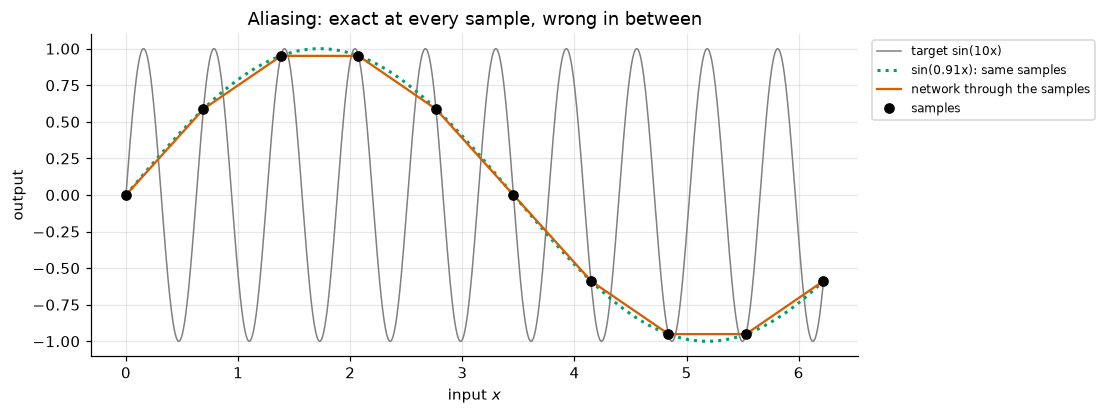

In [32]:
OMEGA = 10.0
h_alias = 2.2 * math.pi / OMEGA
t_alias = torch.arange(10, dtype=torch.float64) * h_alias              # (10,) sample points in [0, 2π]
f_alias = lambda t: torch.sin(OMEGA * t)
alias_net = interpolating_network(f_alias, t_alias)
x_al = torch.linspace(0, t_alias[-1].item(), 4001, dtype=torch.float64)
print(f"max error at the 10 samples: {(run(alias_net, t_alias) - f_alias(t_alias)).abs().max().item():.1e}")
print(f"max error between them:      {(run(alias_net, x_al) - f_alias(x_al)).abs().max().item():.3f}")

# A much slower sine passes through the very same samples:
omega_alias = OMEGA - 2 * math.pi / h_alias
print(f"alias frequency {omega_alias:.4f};  max |sin(10 t) − sin({omega_alias:.3f} t)| at the samples:"
      f" {(f_alias(t_alias) - torch.sin(omega_alias * t_alias)).abs().max().item():.1e}")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(x_al, f_alias(x_al), color="gray", lw=1, label="target sin(10x)")
ax.plot(x_al, torch.sin(omega_alias * x_al), ":", color=COLORS[2], lw=2, label=f"sin({omega_alias:.2f}x): same samples")
ax.plot(x_al, run(alias_net, x_al), color=COLORS[1], label="network through the samples")
ax.plot(t_alias, f_alias(t_alias), "o", color="k", label="samples")
ax.set_xlabel("input $x$")
ax.set_ylabel("output")
ax.set_title("Aliasing: exact at every sample, wrong in between")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.show()

The network is exact at all 10 samples (error $\sim 10^{-16}$) and off by almost 2 between them. The samples are equally consistent with the slow sine $\sin(0.91x)$ (dotted): the jump of $2\pi$ in phase between samples is invisible, the same effect that makes wagon wheels appear to turn backwards on film. No network, and no learning algorithm, can tell these targets apart from these samples. To recover a sine one needs **more than two samples per period** (the Nyquist–Shannon sampling rate, stated without proof), and in general some assumption about how the target behaves between samples. Choosing such assumptions — the **inductive bias** of a model — is a recurring theme of the course, starting with notebook 22.

## Exercises

### Exercise 1 (modify): smoothness and the cost of accuracy

The cell below builds the interpolating network for a target `TARGET` on $[-1, 1]$ with `H` units, plots it, and prints the max error for $H, 2H, 4H, 8H$ together with the ratio between consecutive errors.

1. Run it as given ($x^2$).
2. Change `TARGET` to `torch.abs`, then to `lambda x: torch.sigmoid(50 * x)`, then to the step `lambda x: (x >= 0.1).double()`, and change `H` (try 5, 8, 10).
3. For each target, how does the error change when $H$ doubles? Relate the answer to the smoothness of the target, and explain any case where the error does not shrink at all, or is exactly 0.

<details>
<summary><b>💡 Hint</b></summary>

For $x^2$, $f'' = 2$ everywhere, so the bound $Mh^2/8$ is $h^2/4$ (and is attained exactly: work out the error on one segment). For $|x|$ ask whether $x = 0$ is a knot. For the step, recall Section 4: what is the largest error of any continuous approximant?

</details>

H =   8: max error 1.563e-02   previous / this = —
H =  16: max error 3.906e-03   previous / this = 4.00
H =  32: max error 9.766e-04   previous / this = 4.00
H =  64: max error 2.441e-04   previous / this = 4.00


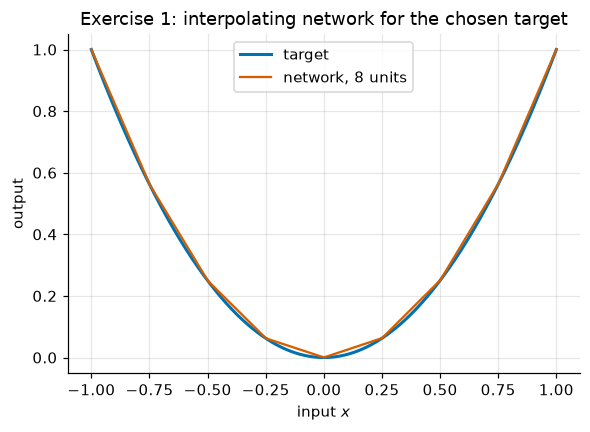

In [33]:
TARGET = lambda x: x**2
H = 8

x_ex = torch.linspace(-1, 1, 200_001, dtype=torch.float64)
errors = []
for mult in [1, 2, 4, 8]:
    net = interpolating_network(TARGET, torch.linspace(-1, 1, mult * H + 1, dtype=torch.float64))
    errors.append((run(net, x_ex) - TARGET(x_ex)).abs().max().item())
ratios = ["—"] + [f"{errors[i - 1] / errors[i]:.2f}" if errors[i] > 0 else "inf" for i in range(1, 4)]
for mult, e, r in zip([1, 2, 4, 8], errors, ratios):
    print(f"H = {mult * H:3d}: max error {e:.3e}   previous / this = {r}")

net = interpolating_network(TARGET, torch.linspace(-1, 1, H + 1, dtype=torch.float64))
plt.plot(x_ex, TARGET(x_ex), color=COLORS[0], lw=2, label="target")
plt.plot(x_ex, run(net, x_ex), color=COLORS[1], label=f"network, {H} units")
plt.xlabel("input $x$")
plt.ylabel("output")
plt.title("Exercise 1: interpolating network for the chosen target")
plt.legend()
plt.show()

*Your answer:*

### Exercise 2 (implement): counting linear pieces

Section 5 counted pieces on a grid chosen so that every kink was a grid point. Write a general `count_linear_pieces(f, a, b, n=10001, tol=1e-6)` that counts the linear pieces of a continuous piecewise-linear function on $[a, b]$ from its values on `n` equally spaced points (use `float64`):

1. compute the slope on each of the $n - 1$ grid cells;
2. mark each place where the slope changes between consecutive cells by more than `tol`;
3. a kink that falls strictly *inside* a grid cell gives that cell an in-between slope, so it shows up as **two consecutive** marks: count each run of consecutive marks as **one** kink;
4. return the number of kinks plus 1, as an `int`.

`f` maps a 1-D `float64` tensor of shape `(n,)` to shape `(n,)`. Assume the grid is fine enough that kinks are at least two cells apart.

<details>
<summary><b>💡 Hint</b></summary>

`x = torch.linspace(a, b, n, dtype=torch.float64)`, `slopes = torch.diff(f(x)) / torch.diff(x)`, `changed = torch.diff(slopes).abs() > tol` (a boolean tensor of length $n - 2$). A run starts wherever `changed[i]` is true and `changed[i - 1]` is not (or `i == 0`); count those starts.

</details>

In [ ]:
def count_linear_pieces(f, a, b, n=10001, tol=1e-6):
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
for _k in range(1, 6):
    _got = count_linear_pieces(lambda t, _k=_k: run(tent_power(_k), t), 0.0, 1.0)
    check(_got == 2**_k, f"tent_power({_k}) has {2**_k} pieces, count_linear_pieces returned {_got}")
check(count_linear_pieces(torch.abs, -1.0, 1.0, n=1000) == 2, "|x| on [-1, 1] has 2 pieces (here 0 is inside a grid cell)")
check(count_linear_pieces(lambda t: 3 * t + 1, -1.0, 1.0) == 1, "a straight line has 1 piece")
_net_exp = interpolating_network(torch.exp, torch.linspace(0, 2, 6, dtype=torch.float64))
check(count_linear_pieces(lambda t: run(_net_exp, t), 0.0, 2.0) == 5, "the interpolant of exp at 6 knots has 5 pieces")
check(isinstance(count_linear_pieces(torch.abs, -1.0, 1.0), int), "return an int")
passed("Exercise 2")

### Exercise 3 (debug): an interpolating network with two bugs

`build_interpolant(f, knots)` is meant to do what `interpolating_network` does, and the buggy version (in the comments) runs without errors and returns a network of the right shape. But it contains **two** bugs, each a plausible slip when deriving the weights. Compare it with `linear_interp`, find both bugs, and write the corrected body.

<details>
<summary><b>💡 Hint</b></summary>

Evaluate the buggy network at the knots and compare with `f(knots)`. Where are its kinks (where is $\operatorname{relu}(x + b_k)$ zero)? And what is the slope of the buggy network on the second segment, if every output weight is a slope rather than a slope *change*? The demonstration cell after the check prints both effects.

</details>

In [ ]:
def build_interpolant(f, knots):
    t = knots.double()
    y = f(t)
    H = len(t) - 1
    s = (y[1:] - y[:-1]) / (t[1:] - t[:-1])
    net = nn.Sequential(nn.Linear(1, H, dtype=torch.float64), nn.ReLU(), nn.Linear(H, 1, dtype=torch.float64))
    with torch.no_grad():
        net[0].weight.fill_(1.0)
        # Buggy version:
        #     net[0].bias.copy_(t[:-1])
        #     net[2].weight.copy_(s.unsqueeze(0))
        # YOUR CODE HERE
        raise NotImplementedError
        net[2].bias.fill_(y[0].item())
    return net

In [ ]:
_knots = torch.tensor([-2.0, -1.2, -0.3, 0.5, 1.4, 2.0], dtype=torch.float64)
_f = lambda t: torch.cos(2 * t) + 0.3 * t
_net = build_interpolant(_f, _knots)
_x = -2 + 4 * torch.rand(5000, generator=torch.Generator().manual_seed(3), dtype=torch.float64)
check_close(run(_net, _x), linear_interp(_x, _knots, _f(_knots)), "build_interpolant output", rtol=0, atol=1e-10)
check_close(run(_net, _knots), _f(_knots), "values at the knots", rtol=0, atol=1e-10)
passed("Exercise 3")

To see what each bug does, here is the buggy constructor run directly on the same example:

In [38]:
def build_interpolant_buggy(f, knots, fix_bias=False, fix_weights=False):
    t = knots.double()
    y = f(t)
    H = len(t) - 1
    s = (y[1:] - y[:-1]) / (t[1:] - t[:-1])
    net = nn.Sequential(nn.Linear(1, H, dtype=torch.float64), nn.ReLU(), nn.Linear(H, 1, dtype=torch.float64))
    with torch.no_grad():
        net[0].weight.fill_(1.0)
        net[0].bias.copy_(-t[:-1] if fix_bias else t[:-1])
        net[2].weight.copy_((torch.cat([s[:1], s[1:] - s[:-1]]) if fix_weights else s).unsqueeze(0))
        net[2].bias.fill_(y[0].item())
    return net


_knots = torch.tensor([-2.0, -1.2, -0.3, 0.5, 1.4, 2.0], dtype=torch.float64)
_f = lambda t: torch.cos(2 * t) + 0.3 * t
_x = torch.linspace(-2, 2, 2001, dtype=torch.float64)
for fb, fw, label in [(False, False, "both bugs"), (True, False, "bias fixed only"), (False, True, "weights fixed only"), (True, True, "both fixed")]:
    net_b = build_interpolant_buggy(_f, _knots, fix_bias=fb, fix_weights=fw)
    err = (run(net_b, _x) - linear_interp(_x, _knots, _f(_knots))).abs().max().item()
    print(f"{label:18s}: kinks at {[round(v, 2) for v in (-net_b[0].bias).tolist()]}   max error {err:.3f}")

both bugs         : kinks at [2.0, 1.2, 0.3, -0.5, -1.4]   max error 1.819
bias fixed only   : kinks at [-2.0, -1.2, -0.3, 0.5, 1.4]   max error 4.416
weights fixed only: kinks at [2.0, 1.2, 0.3, -0.5, -1.4]   max error 0.841
both fixed        : kinks at [-2.0, -1.2, -0.3, 0.5, 1.4]   max error 0.000


### Exercise 4 (investigate): how width scales with frequency, and with dimension

Target $f(x) = \sin(\omega x)$ on $[0, 2\pi]$ for $\omega \in \{1, 2, 4, 8\}$. For each $\omega$, find the **smallest** number of units $H$ (equally spaced knots, the constructed network of Section 2) for which the max error on a dense grid is below $0.01$. Complete `min_units`, then run the cell: it plots $H$ against $\omega$ on log–log axes and fits the slope. Then answer in the markdown cell:

1. How does the required $H$ scale with $\omega$? Derive the prediction from the bound $Mh^2/8$ (what is $M$ for $\sin(\omega x)$?) and compare it with the measured counts.
2. Suppose the target were a function of $D$ variables, approximated to the same resolution $h$ in every direction with a grid-based construction such as Section 4's towers. Roughly how many units would it need? Evaluate for $D = 1, 2, 10$ with $1/h = 30$.

<details>
<summary><b>💡 Hint</b></summary>

Start at $H = 1$ and increase $H$ by 1 until `max_interp_error(f, 0.0, 2 * math.pi, H) < tol`; `max_interp_error` is defined in Section 3. It takes a few hundred tries for $\omega = 8$, well under a second. For the prediction: $M = \omega^2$ and $h = 2\pi/H$.

</details>

In [ ]:
def min_units(omega, tol=0.01):
    f = lambda x: torch.sin(omega * x)
    # YOUR CODE HERE
    raise NotImplementedError


omegas = [1, 2, 4, 8]
needed = [min_units(om) for om in omegas]
predicted = [math.ceil(2 * math.pi * om / math.sqrt(8 * 0.01)) for om in omegas]
for om, n_, p_ in zip(omegas, needed, predicted):
    print(f"ω = {om}: smallest H = {n_:4d}   bound-based prediction ceil(2πω / √(8·0.01)) = {p_:4d}")
log_om = torch.log(torch.tensor(omegas, dtype=torch.float64))
fit = torch.linalg.lstsq(torch.stack([log_om, torch.ones_like(log_om)], 1),
                         torch.log(torch.tensor(needed, dtype=torch.float64)).unsqueeze(1)).solution
print(f"fitted log-log slope: {fit[0].item():.3f}")

plt.loglog(omegas, needed, "o-", label=f"smallest H for max error < 0.01 (slope {fit[0].item():.2f})")
plt.loglog(omegas, predicted, ":", label="prediction from $\\omega^2 h^2/8 = 0.01$")
plt.xlabel("frequency $\\omega$")
plt.ylabel("hidden units $H$")
plt.title("Exercise 4: width needed for sin(ωx) on [0, 2π]")
plt.legend(fontsize=8)
plt.show()

*Your conclusion:*

## Summary and what's next

- A ReLU unit $a\,\operatorname{relu}(wx + b)$ is a **hinge** with its kink at $x = -b/w$, where the slope jumps by $a|w|$. A one-hidden-layer network of one variable is a **continuous piecewise-linear** function with at most $H$ kinks.
- Setting $b_k = -t_k$ and output weights to the **changes in slope** gives a network that **is** the piecewise-linear interpolant through $H + 1$ knots, exactly (we verified it to $10^{-15}$).
- For targets with $|f''| \le M$ the sup-norm error is at most $Mh^2/8$, so it falls like $1/H^2$; rough targets converge more slowly ($\sqrt{|x|}$: like $H^{-1/2}$), and jumps not at all in the sup norm.
- **Universal approximation** (Cybenko 1989; Hornik 1991; Leshno et al. 1993): one hidden layer with any non-polynomial activation approximates any continuous function on a compact set to any accuracy in the sup norm. It says nothing about the number of units (which can grow like $(1/h)^D$), how to find the weights, behavior outside the compact set, or generalization from samples, and it does not cover discontinuous targets — although **thresholded** outputs can classify exactly.
- **Depth** can be exponentially more efficient: $k$ composed tent maps give $2^k$ pieces with $2k$ units, while one hidden layer needs at least $2^k - 1$ (Telgarsky 2016).
- **Representing ≠ learning ≠ generalizing.** A good 19-unit network exists for 20 noisy samples of $\sin$, but training drove the training error far below the noise and the held-out error up; ReLU networks extrapolate linearly; and with too few samples (aliasing), a network can fit every sample exactly and be wrong everywhere else.

This completes Chapter 2. We started from one perceptron and its linear decision boundary, saw why a single linear model fails on XOR, rings and spirals, and ended knowing **what** networks of simple units can represent: Boolean functions, polygonal regions, and — approximately — any continuous function. What we have not done is train such networks reliably. So far we built them by hand or called `loss.backward()` on small examples. **Chapter 3** builds multilayer perceptrons from scratch (notebook 13), derives **backpropagation** by hand (14), and then studies the choices that decide whether training works: activations (16), loss functions (17), initialization (18), optimizers (19), and when depth helps in practice (20).